# M5 Retail Demand Forecasting — Notebook 6: Inventory Simulation

**This notebook:** measure whether a better forecast leads to better inventory decisions, using a simple replenishment simulation.

| | |
|---|---|
| **Inputs** | `m5_sample_long_ext.parquet`, `preds_holdout_h28.parquet` (Notebook 5), `preds_lgbm_h28.parquet` (Notebook 3), `feature_config.json` |
| **Output** | `inventory_results.json` |

**Important.** M5 contains no inventory levels, supplier lead times or costs. Everything operational in this notebook is an **assumption** (listed below, and varied in a sensitivity analysis). Results are statements about a **simulation under stated assumptions**, not real savings.

**Policies compared**

| Policy | Demand estimate |
|---|---|
| **A: moving average** | average sales of the last 28 days (a simple rule often used in practice) |
| **B: LightGBM** | the model's 28-day forecast |
| **Oracle** | the actual future demand (perfect forecast). Not achievable; an upper bound on what forecasting can deliver |

**Fairness.** All policies face the same demand, the same costs and the same starting inventory. The safety-stock formula is identical for A and B (the oracle needs none). Forecasts are strictly out-of-sample: the three validation folds (each from a model that had not seen that window) and the final holdout form **four consecutive 28-day blocks = 112 days** (2016-02-01 to 2016-05-22).

---
## 1. Setup and assumptions

| Assumption | Default | Meaning |
|---|---|---|
| Review period `R` | 7 days | orders are placed weekly |
| Lead time `L` | 7 days | fixed delay between ordering and arrival |
| Target service level | 95% | used for the safety stock (z = 1.645) |
| Unit cost | 70% of the selling price | purchase cost |
| Holding cost | 25% per year of unit cost | charged per unit per day |
| Lost-sale cost | margin x 1.0 | unmet demand is lost (no backorders) |
| Ordering cost | $2 per order | fixed cost per order |
| Pack size | 1 unit | no minimum order quantity |

The selling price is the actual M5 `sell_price`; everything else is assumed.

In [1]:
import json, time, warnings
from statistics import NormalDist
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.figsize"] = (11, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

SEED = 42
T = 28          # each block is 28 days long

# ================= ASSUMPTIONS (everything can be changed here) =================
ASSUME = dict(
    R=7,               # review period (days)
    L=7,               # lead time (days)
    SL=0.95,           # target service level (used for the safety stock)
    COST_FRAC=0.70,    # unit cost = 70% of price
    HOLD_RATE=0.25,    # holding cost, per year, as fraction of unit cost
    PEN_MULT=1.0,      # lost-sale cost = margin x PEN_MULT
    ORDER_COST=2.0,    # $ per order
    MIN_HIST=56,       # a series needs at least this many available days before the origin
    SIGMA_DAYS=56,     # number of past days used to estimate demand variability
)
print(json.dumps(ASSUME, indent=2))

def find_file(name):
    for root in [Path(".")] + ([Path("..")] if not Path("data").exists() else []) + [Path("/kaggle/working"), Path("/kaggle/input")]:
        if root.exists():
            hits = list(root.rglob(name))
            if hits:
                return hits[0]
    raise FileNotFoundError(f"{name} not found. Run Notebooks 1-5 first.")

EXT_PATH  = find_file("m5_sample_long_ext.parquet")
PRED_PATH = find_file("preds_lgbm_h28.parquet")
HOLD_PATH = find_file("preds_holdout_h28.parquet")
CFG_PATH  = find_file("feature_config.json")
OUT = Path("/kaggle/working/processed") if Path("/kaggle/working").exists() else (Path("../data/processed") if (not Path("data").exists() and Path("../data").exists()) else Path("data/processed"))
OUT.mkdir(parents=True, exist_ok=True)

{
  "R": 7,
  "L": 7,
  "SL": 0.95,
  "COST_FRAC": 0.7,
  "HOLD_RATE": 0.25,
  "PEN_MULT": 1.0,
  "ORDER_COST": 2.0,
  "MIN_HIST": 56,
  "SIGMA_DAYS": 56
}


In [2]:
cfg = json.loads(CFG_PATH.read_text())
ext = pd.read_parquet(EXT_PATH, columns=["id", "date", "sales", "sell_price", "is_available"])
ext["date"] = pd.to_datetime(ext["date"]); ext["id"] = ext["id"].astype(str)
ext = ext.sort_values(["id", "date"]).reset_index(drop=True)
ids = ext["id"].drop_duplicates().tolist()
dates = pd.DatetimeIndex(np.sort(ext["date"].unique()))
ni, nd = len(ids), len(dates)
assert len(ext) == ni * nd

def to_wide(v):
    return pd.DataFrame(np.asarray(v, dtype="float64").reshape(ni, nd).T, index=dates, columns=ids)

S  = to_wide(ext["sales"].where(ext["is_available"]))      # NaN = unavailable
Pf = to_wide(ext["sell_price"]).ffill()                     # price forward-filled
print("Panel:", S.shape, "|", dates.min().date(), "->", dates.max().date())

# ---- 4 contiguous out-of-sample blocks ----
fp = pd.read_parquet(PRED_PATH); fp["id"] = fp["id"].astype(str); fp["date"] = pd.to_datetime(fp["date"])
hp = pd.read_parquet(HOLD_PATH); hp["id"] = hp["id"].astype(str); hp["date"] = pd.to_datetime(hp["date"])

BLOCK_DEFS = []
for f in cfg["folds"]:
    sub = fp[fp["fold"] == f["fold"]]
    BLOCK_DEFS.append((f"fold{f['fold']}", pd.Timestamp(f["valid_start"]), pd.Timestamp(f["valid_end"]),
                       sub.pivot(index="date", columns="id", values="lgbm_final")))
hs, he = hp["date"].min(), hp["date"].max()
BLOCK_DEFS.append(("holdout", hs, he, hp.pivot(index="date", columns="id", values="lgbm_final")))
BLOCK_DEFS.sort(key=lambda b: b[1])
for n, a, b, _ in BLOCK_DEFS:
    print(f"{n:8s}: {a.date()} -> {b.date()}")
assert all((BLOCK_DEFS[i + 1][1] - BLOCK_DEFS[i][2]).days == 1 for i in range(len(BLOCK_DEFS) - 1)), "Blocks are not contiguous"

Panel: (1941, 999) | 2011-01-29 -> 2016-05-22
fold3   : 2016-02-01 -> 2016-02-28
fold2   : 2016-02-29 -> 2016-03-27
fold1   : 2016-03-28 -> 2016-04-24
holdout : 2016-04-25 -> 2016-05-22


---
## 2. How the simulator works

**One day for one series**
1. Orders due today arrive (on-hand stock increases).
2. On a review day an order is placed.
3. Demand `D` occurs: sales = `min(on-hand, D)`; the remainder is a lost sale.
4. The stock left at the end of the day incurs the holding cost.

**Order-up-to (base-stock) policy.** On a review day:
```
inventory position = on-hand + on-order
target level S     = expected demand over (L + R) days + safety stock
order quantity     = max(0, S - inventory position)
```
An order placed now arrives after `L` days and must cover demand until the next order can arrive, which is `L + R` days.

**Safety stock** protects against demand exceeding the forecast: `z * sigma * sqrt(L + R)`, where `sigma` is the standard deviation of the series' daily sales over the 56 days before the block (identical for all policies) and `z` follows from the service level. This is a normal approximation, which fits zero-heavy intermittent demand poorly; since it is the same for all policies the comparison remains fair, but absolute service levels are only approximate.

**Starting stock** is identical for all policies: `ceil(28-day average x (L + R))`.

**Only the forecast differs between policies:** A uses the flat moving average, B the sum of the LightGBM forecasts over the next `L + R` days, the oracle the actual demand.

**Edge handling.** The forecasts cover 28 days; beyond the block the last-7-day average is used for all policies. Orders that would arrive after the block do not affect the block's costs and are not simulated. Only series that were available for all 28 days and had at least 56 days of history at the origin are used.

In [3]:
def make_block(name, vs, ve, fc, A):
    origin = vs - pd.Timedelta(days=1)
    bd = dates[(dates >= vs) & (dates <= ve)]
    assert len(bd) == T
    hist_ok = S.loc[:origin].notna().sum() >= A["MIN_HIST"]
    avail_all = S.loc[bd].notna().all()
    cand = [i for i in S.columns[(hist_ok & avail_all).to_numpy()] if i in fc.columns and fc.loc[bd, i].notna().all()]
    D  = S.loc[bd, cand].to_numpy()
    F  = fc.loc[bd, cand].to_numpy()
    ma = S.loc[origin - pd.Timedelta(days=27):origin, cand].mean().fillna(0).to_numpy()
    sg = S.loc[origin - pd.Timedelta(days=A["SIGMA_DAYS"] - 1):origin, cand].std().fillna(0).to_numpy()
    v  = Pf.loc[bd, cand].mean()
    v  = v.fillna(Pf.loc[:origin, cand].iloc[-1]).fillna(v.median()).clip(lower=0.01).to_numpy()
    return {"name": name, "ids": np.array(cand), "D": D, "F": F, "ma": ma, "sigma": sg, "price": v, "origin": origin}

BLOCKS = [make_block(n, a, b, fc, ASSUME) for n, a, b, fc in BLOCK_DEFS]
print(pd.DataFrame([{"block": b["name"], "series_used": len(b["ids"]), "total_demand_units": b["D"].sum(),
                     "avg_price": b["price"].mean()} for b in BLOCKS]))

     block  series_used  total_demand_units  avg_price
0    fold3          997          37,971.000      4.671
1    fold2          998          38,827.000      4.673
2    fold1          998          38,564.000      4.676
3  holdout          999          40,223.000      4.674


In [4]:
def simulate_block(block, policy, L, R, z, pen_mult, A):
    D, n = block["D"], block["D"].shape[1]
    ma, sg, v = block["ma"], block["sigma"], block["price"]
    c = A["COST_FRAC"] * v
    hold_u = A["HOLD_RATE"] / 365.0 * c               # per unit per day
    pen_u  = (v - c) * pen_mult                       # per unit lost
    hz = L + R

    if policy == "A":                                  # moving average: flat rate
        Fx = np.tile(ma, (T + hz, 1)); ss = z * sg * np.sqrt(hz)
    elif policy == "B":                                # LightGBM forecast
        F = block["F"]; Fx = np.vstack([F, np.tile(F[-7:].mean(0), (hz, 1))]); ss = z * sg * np.sqrt(hz)
    elif policy == "oracle":                           # perfect foresight, no safety stock needed
        Fx = np.vstack([D, np.tile(D[-7:].mean(0), (hz, 1))]); ss = np.zeros(n)
    else:
        raise ValueError(policy)
    cum = np.vstack([np.zeros((1, n)), np.cumsum(Fx, axis=0)])      # cum[k] = sum of the first k days

    onhand = np.ceil(ma * hz)                                        # starting stock: identical for all policies
    pipe = np.zeros((T + L + 1, n))
    hold_cost = np.zeros(n); lost_units = np.zeros(n); stockout_days = np.zeros(n)
    inv_sum = np.zeros(n); orders = np.zeros(n)
    for d in range(T):
        onhand = onhand + pipe[d]                                    # 1) arrivals
        if d % R == 0 and d + L < T:                                 # 2) review: place an order (only if it arrives within the block)
            target = (cum[d + hz] - cum[d]) + ss
            ip = onhand + pipe[d + 1:].sum(axis=0)
            qty = np.ceil(np.maximum(0.0, target - ip))
            pipe[d + L] += qty
            orders += (qty > 0)
        sold = np.minimum(onhand, D[d]); lost = D[d] - sold          # 3) demand
        onhand = onhand - sold
        hold_cost += hold_u * onhand                                 # 4) holding cost
        lost_units += lost; stockout_days += (lost > 0); inv_sum += onhand
    return pd.DataFrame({
        "id": block["ids"], "block": block["name"], "demand": D.sum(0), "lost_units": lost_units,
        "stockout_days": stockout_days, "avg_inv_units": inv_sum / T, "avg_inv_value": inv_sum / T * c,
        "orders": orders, "hold_cost": hold_cost, "order_cost": orders * A["ORDER_COST"], "lost_cost": lost_units * pen_u})

def run(policy, L=None, SL=None, pen_mult=None, A=ASSUME, blocks=None):
    L = A["L"] if L is None else L; SL = A["SL"] if SL is None else SL; pen_mult = A["PEN_MULT"] if pen_mult is None else pen_mult
    z = NormalDist().inv_cdf(SL)
    out = [simulate_block(b, policy, L, A["R"], z, pen_mult, A) for b in (blocks or BLOCKS)]
    df = pd.concat(out, ignore_index=True)
    df["total_cost"] = df["hold_cost"] + df["order_cost"] + df["lost_cost"]
    return df

def summarize(df):
    dem = df["demand"].sum()
    return {"fill_rate_%": (1 - df["lost_units"].sum() / dem) * 100,
            "stockout_day_rate_%": df["stockout_days"].sum() / (len(df) * T) * 100,
            "avg_inventory_units": df["avg_inv_units"].mean(), "avg_inventory_value_$": df["avg_inv_value"].mean(),
            "holding_cost": df["hold_cost"].sum(), "ordering_cost": df["order_cost"].sum(),
            "lost_sales_cost": df["lost_cost"].sum(), "total_cost": df["total_cost"].sum(), "orders": df["orders"].sum()}

# ---- sanity checks (is the simulator behaving correctly?) ----
r_or = run("oracle"); r_a = run("A"); r_b = run("B")
for nm, r_ in [("A", r_a), ("B", r_b), ("oracle", r_or)]:
    assert (r_["lost_units"] >= -1e-9).all() and (r_["lost_units"] <= r_["demand"] + 1e-9).all()
    assert (r_["avg_inv_units"] >= 0).all()
print("Simulator sanity checks PASS (lost <= demand, inventory >= 0)")

Simulator sanity checks PASS (lost <= demand, inventory >= 0)


---
## 3. Base scenario

Default assumptions (L = 7, service level 95%, lost-sale cost = margin).

- **Fill rate:** share of demand that was served (higher is better).
- **Stock-out-day rate:** share of series-days with unmet demand.
- **Average inventory** in units and in dollars.
- **Holding, ordering and lost-sales cost**, and the total (lower is better).

The policies end up with different fill rates in this table, and holding more stock buys a higher fill rate at a higher holding cost. A comparison of total cost alone can therefore mislead; the fair comparison is in Section 4.

In [5]:
base = pd.DataFrame({"A: moving avg": summarize(r_a), "B: LightGBM": summarize(r_b), "Oracle (upper bound)": summarize(r_or)})
base.loc["total_cost_vs_A_%"] = (base.loc["total_cost"] / base.loc["total_cost", "A: moving avg"] - 1) * 100
print(f"Series-blocks simulated: {len(r_a)} | series: {r_a['id'].nunique()} | demand units: {r_a['demand'].sum():,.0f}")
base

Series-blocks simulated: 3992 | series: 999 | demand units: 155,585


,A: moving avg,B: LightGBM,Oracle (upper bound)
fill_rate_%,92.985,93.485,98.985
stockout_day_rate_%,3.020,2.672,0.565
avg_inventory_units,13.748,13.461,8.124
avg_inventory_value_$,34.610,33.974,20.243
holding_cost,"2,649.705","2,600.991","1,549.813"
ordering_cost,"20,590.000","20,992.000","15,022.000"
lost_sales_cost,"11,244.771","10,323.124","1,654.117"
total_cost,"34,484.476","33,916.114","18,225.930"
orders,"10,295.000","10,496.000","7,511.000"
total_cost_vs_A_%,0.000,-1.648,-47.147


**Result (base scenario, 112 days, 999 series).**

| | A: moving average | B: LightGBM | Oracle |
|---|---|---|---|
| Fill rate | 93.0% | 93.5% | 99.0% |
| Stock-out-day rate | 3.0% | 2.7% | 0.6% |
| Holding cost | $2,650 | $2,601 | $1,550 |
| Ordering cost | $20,590 | $20,992 | $15,022 |
| Lost-sales cost | $11,245 | $10,323 | $1,654 |
| **Total cost** | $34,484 | $33,916 (-1.6%) | $18,226 (-47.1%) |

B is 1.6% cheaper with a slightly higher fill rate. Two things stand out: the oracle is far cheaper, so most of the cost comes from demand randomness rather than from the quality of the mean forecast; and ordering cost (about 60% of the total) is nearly identical across policies because every policy orders weekly, which dilutes the percentage differences. Looking only at the policy-dependent costs (holding + lost sales), B is about 7% lower ($12,924 vs $13,895).

---
## 4. Cost versus service level (the fair comparison)

In the base scenario A and B ended up at different fill rates, so comparing their costs is like comparing apples with oranges.

**Frontier.** Each policy is run at many target service levels (50% to 99.5%). Every level gives a (fill rate, total cost) point; joining the points gives a curve showing the **cheapest cost for each achieved fill rate**. The policy whose curve lies lower is cheaper at every service level.

Two numbers are derived:
1. **Equal-fill comparison:** the cost of B interpolated at the fill rate A reached in the base scenario, compared with A's cost.
2. **Minimum-cost comparison:** each policy at its own cost-minimising service level.

A (SL=95%): fill rate 92.99% | total cost $34,484
B's cost at the same fill rate (interpolated): $34,536
=> At equal service, B vs A: +0.15% total cost

Cost-optimal SL: A = 99.5% (cost $32,235) | B = 99.5% (cost $31,697) | Oracle $18,226
=> Each policy at its own best level: B vs A = -1.67% | Oracle vs A = -43.46%


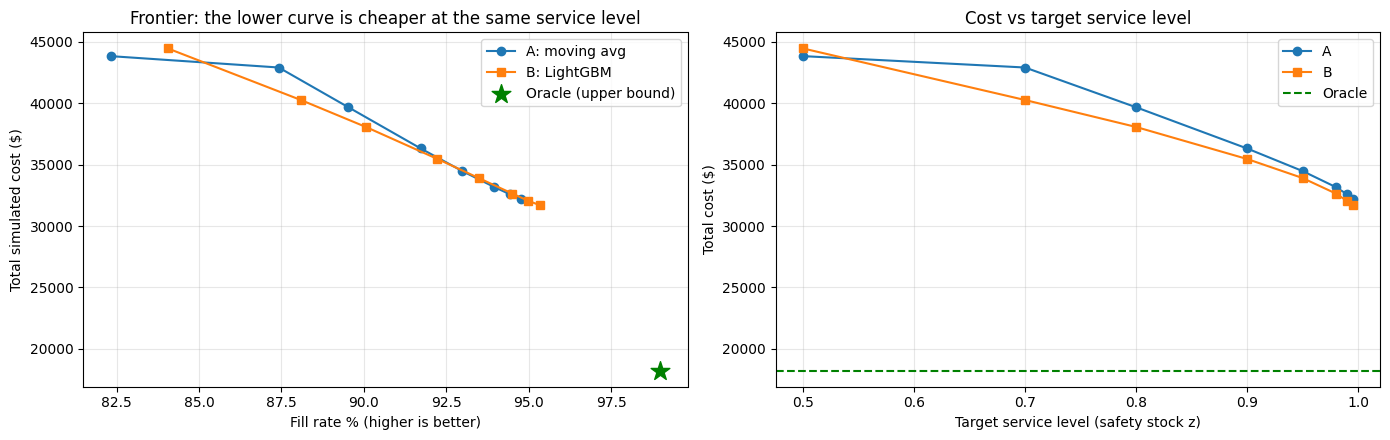

A                                                                       B                                                            
      fill_rate_% avg_inventory_units holding_cost lost_sales_cost total_cost fill_rate_% avg_inventory_units holding_cost lost_sales_cost total_cost
SL                                                                                                                                                   
0.500      82.316               8.590    1,645.616      29,213.613 43,847.228      84.055               8.759    1,683.135      26,316.133 44,473.268
0.700      87.419              10.103    1,943.357      20,536.657 42,920.014      88.091              10.018    1,929.667      19,476.355 40,272.022
0.800      89.531              11.080    2,133.276      17,004.910 39,682.186      90.062              10.912    2,102.640      16,105.586 38,076.226
0.900      91.727              12.512    2,411.352      13,322.238 36,323.590      92.234              12.264    2,367.260      12,420.086 35,467.346
0.950      92.985              13.748    2,649.705      11,244.771 34,484.476      93.485              13.461    2,600.991      10,323.124 33,916.114
0.980      93.962              15.191    2,932.186       9,652.932 33,175.119      94.502              14.869    2,875.116       8,649.846 32,650.962
0.990      94.428              16.165    3,118.962       8,887.060 32,596.021      94.994              15.837    3,063.898       7,841.500 32,053.399
0.995      94.762              17.079    3,297.799       8,346.952 32,234.751      95.345              16.726    3,236.337       7,282.206 31,696.543

In [6]:
SL_GRID = [0.50, 0.70, 0.80, 0.90, 0.95, 0.98, 0.99, 0.995]

def frontier(policy, L=None, pen_mult=None):
    rows = []
    for sl in SL_GRID:
        s = summarize(run(policy, L=L, SL=sl, pen_mult=pen_mult)); s["SL"] = sl
        rows.append(s)
    return pd.DataFrame(rows).set_index("SL")

fa, fb = frontier("A"), frontier("B")
orc = summarize(r_or)

def cost_at_fill(front, fill):
    f = front.sort_values("fill_rate_%")
    return float(np.interp(fill, f["fill_rate_%"], f["total_cost"]))

fill_A = fa.loc[ASSUME["SL"], "fill_rate_%"]
costA = fa.loc[ASSUME["SL"], "total_cost"]
costB_at = cost_at_fill(fb, fill_A)
inrange = fb["fill_rate_%"].min() <= fill_A <= fb["fill_rate_%"].max()

print(f"A (SL={ASSUME['SL']:.0%}): fill rate {fill_A:.2f}% | total cost ${costA:,.0f}")
print(f"B's cost at the same fill rate (interpolated{'' if inrange else ', OUTSIDE THE RANGE, not extrapolated'}): ${costB_at:,.0f}")
print(f"=> At equal service, B vs A: {(costB_at / costA - 1) * 100:+.2f}% total cost")

minA, minB = fa["total_cost"].min(), fb["total_cost"].min()
print(f"\nCost-optimal SL: A = {fa['total_cost'].idxmin():.1%} (cost ${minA:,.0f}) | B = {fb['total_cost'].idxmin():.1%} (cost ${minB:,.0f}) | Oracle ${orc['total_cost']:,.0f}")
print(f"=> Each policy at its own best level: B vs A = {(minB / minA - 1) * 100:+.2f}% | Oracle vs A = {(orc['total_cost'] / minA - 1) * 100:+.2f}%")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(fa["fill_rate_%"], fa["total_cost"], "o-", label="A: moving avg")
ax[0].plot(fb["fill_rate_%"], fb["total_cost"], "s-", label="B: LightGBM")
ax[0].scatter([orc["fill_rate_%"]], [orc["total_cost"]], marker="*", s=200, color="green", label="Oracle (upper bound)", zorder=5)
ax[0].set_xlabel("Fill rate % (higher is better)"); ax[0].set_ylabel("Total simulated cost ($)")
ax[0].set_title("Frontier: the lower curve is cheaper at the same service level"); ax[0].legend()

ax[1].plot(fa.index, fa["total_cost"], "o-", label="A"); ax[1].plot(fb.index, fb["total_cost"], "s-", label="B")
ax[1].axhline(orc["total_cost"], color="green", ls="--", label="Oracle")
ax[1].set_xlabel("Target service level (safety stock z)"); ax[1].set_ylabel("Total cost ($)"); ax[1].set_title("Cost vs target service level"); ax[1].legend()
plt.tight_layout(); plt.show()
display(pd.concat({"A": fa[["fill_rate_%", "avg_inventory_units", "holding_cost", "lost_sales_cost", "total_cost"]],
                   "B": fb[["fill_rate_%", "avg_inventory_units", "holding_cost", "lost_sales_cost", "total_cost"]]}, axis=1))

**Result.**
- **Equal-fill:** B's cost is **+0.15%** compared with A, i.e. no difference at the same service level.
- **Minimum cost:** B is 1.7% cheaper than A, each at its own best service level.
- **Oracle:** 43% cheaper than A, so LightGBM closes only about 4% of the gap that a perfect forecast would.
- For both policies the cost-minimising service level was the largest value in the grid (99.5%), yet the achieved fill rate stays near 95% even there. This reflects the weakness of the normal approximation on zero-heavy demand rather than a real optimum.

The two curves nearly coincide: the forecast gain (5.7% in WAPE) translates into very little inventory benefit with this policy.

---
## 5. Bootstrap confidence interval

We resample the series (with replacement) and recompute the **minimum-cost comparison** each time, letting each policy choose its own best service level in every resample. The resampling unit is the series because its four blocks are related. If the interval for B versus A excludes 0, the cost reduction is reliable within this simulation.

In [7]:
def per_id_cost(policy, sl):
    r = run(policy, SL=sl)
    g = r.groupby("id")[["total_cost", "lost_units", "demand"]].sum()
    return g

costsA = {sl: per_id_cost("A", sl) for sl in SL_GRID}
costsB = {sl: per_id_cost("B", sl) for sl in SL_GRID}
orc_id = r_or.groupby("id")["total_cost"].sum()
ids_all = sorted(set(orc_id.index))
MA_ = np.vstack([costsA[sl].reindex(ids_all)["total_cost"].to_numpy() for sl in SL_GRID])     # (n_sl, n_series)
MB_ = np.vstack([costsB[sl].reindex(ids_all)["total_cost"].to_numpy() for sl in SL_GRID])
MO_ = orc_id.reindex(ids_all).to_numpy()

rng = np.random.default_rng(SEED)
Bn = 2000; n = len(ids_all)
res_b, res_o = [], []
for _ in range(Bn):
    idx = rng.integers(0, n, n)
    ca = MA_[:, idx].sum(1).min(); cb = MB_[:, idx].sum(1).min(); co = MO_[idx].sum()
    res_b.append((cb / ca - 1) * 100); res_o.append((co / ca - 1) * 100)
pt_b = (MB_.sum(1).min() / MA_.sum(1).min() - 1) * 100
pt_o = (MO_.sum() / MA_.sum(1).min() - 1) * 100
ci_b = np.percentile(res_b, [2.5, 97.5]); ci_o = np.percentile(res_o, [2.5, 97.5])
print(f"B vs A (each policy at its cost-optimal SL): {pt_b:+.2f}%  | 95% CI [{ci_b[0]:+.2f}%, {ci_b[1]:+.2f}%] | P(B cheaper) = {np.mean(np.array(res_b) < 0):.1%}")
print(f"Oracle vs A (upper bound)                   : {pt_o:+.2f}%  | 95% CI [{ci_o[0]:+.2f}%, {ci_o[1]:+.2f}%]")

B vs A (each policy at its cost-optimal SL): -1.67%  | 95% CI [-3.23%, -0.31%] | P(B cheaper) = 99.2%
Oracle vs A (upper bound)                   : -43.46%  | 95% CI [-46.58%, -40.38%]


**Result.** B versus A (each at its best service level): **-1.7%**, 95% CI **-3.2% to -0.3%**, B cheaper in 99.2% of resamples. Oracle versus A: -43.5% (CI -46.6% to -40.4%).

---
## 6. Sensitivity analysis

The cost and lead-time values are assumptions, so a result that holds only for one setting would be fragile. We vary

- the lead time `L` in {3, 7, 14} days,
- the lost-sale cost multiplier in {0.5, 1, 2, 4} x margin.

**Newsvendor intuition.** The optimal service level is `Cu / (Cu + Co)`, where `Cu` is the cost of having one unit too few (lost margin) and `Co` the cost of one unit too many (holding). A higher lost-sale cost raises the optimal service level. Each scenario therefore compares policies at their own cost-optimal service level (and, as a second table, at equal fill rate).

In [8]:
Ls = [3, 7, 14]; PENS = [0.5, 1.0, 2.0, 4.0]
mc = pd.DataFrame(index=[f"L={l}" for l in Ls], columns=[f"pen x{p}" for p in PENS], dtype=float)
orc_gap = mc.copy(); eq = mc.copy()
for l in Ls:
    for p in PENS:
        fa_, fb_ = frontier("A", L=l, pen_mult=p), frontier("B", L=l, pen_mult=p)
        o_ = summarize(run("oracle", L=l, pen_mult=p))["total_cost"]
        mA, mB = fa_["total_cost"].min(), fb_["total_cost"].min()
        mc.loc[f"L={l}", f"pen x{p}"] = (mB / mA - 1) * 100
        orc_gap.loc[f"L={l}", f"pen x{p}"] = (o_ / mA - 1) * 100
        fill = fa_.loc[ASSUME["SL"], "fill_rate_%"]
        eq.loc[f"L={l}", f"pen x{p}"] = (cost_at_fill(fb_, fill) / fa_.loc[ASSUME["SL"], "total_cost"] - 1) * 100
print("B vs A: change in total cost % (each policy at its cost-optimal service level). Negative = LightGBM cheaper:")
display(mc.round(2))
print("B vs A: change in total cost % (at the fill rate A reaches with SL = 95%, i.e. equal service). Negative = LightGBM cheaper:")
display(eq.round(2))
print("Oracle vs A: change in total cost % (the most a forecast could achieve):")
display(orc_gap.round(2))
n_win = int((mc.to_numpy() < 0).sum())
print(f"\nB is cheaper than A in {n_win}/{mc.size} scenarios (minimum-cost comparison).")

B vs A: change in total cost % (each policy at its cost-optimal service level). Negative = LightGBM cheaper:


,pen x0.5,pen x1.0,pen x2.0,pen x4.0
L=3,2.950,-1.280,-3.830,-7.160
L=7,-0.020,-1.670,-3.950,-6.520
L=14,2.830,-0.670,-2.000,-3.300


B vs A: change in total cost % (at the fill rate A reaches with SL = 95%, i.e. equal service). Negative = LightGBM cheaper:


,pen x0.5,pen x1.0,pen x2.0,pen x4.0
L=3,0.790,0.650,0.450,0.220
L=7,0.320,0.150,-0.070,-0.290
L=14,-0.280,-0.340,-0.400,-0.460


Oracle vs A: change in total cost % (the most a forecast could achieve):


,pen x0.5,pen x1.0,pen x2.0,pen x4.0
L=3,-30.100,-37.490,-46.220,-57.670
L=7,-38.000,-43.460,-51.010,-59.510
L=14,-37.430,-40.010,-41.360,-42.690



B is cheaper than A in 10/12 scenarios (minimum-cost comparison).


**Result.** B versus A, change in total cost at each policy's best service level (negative = LightGBM cheaper):

| | pen x0.5 | pen x1 | pen x2 | pen x4 |
|---|---|---|---|---|
| L = 3 | +2.9% | -1.3% | -3.8% | -7.2% |
| L = 7 | 0.0% | -1.7% | -4.0% | -6.5% |
| L = 14 | +2.8% | -0.7% | -2.0% | -3.3% |

B is cheaper in 10 of 12 scenarios; it loses when stock-outs are cheap (0.5x margin) with short or long lead times, and its advantage is largest when stock-outs are expensive. At **equal fill rate**, however, the differences are small and of mixed sign (between -0.5% and +0.8%), consistent with the conclusion above. The oracle gap ranges from about -30% to -60%.

---
## 7. Block by block (holdout separately)

Of the four blocks, the holdout block is the one that influenced no decision (Notebook 5). We check whether the effect is consistent across blocks. The equal-fill and minimum-cost comparisons are computed per block.

In [9]:
rows = []
for b in BLOCKS:
    fa_ = pd.DataFrame([{**summarize(run("A", SL=sl, blocks=[b])), "SL": sl} for sl in SL_GRID]).set_index("SL")
    fb_ = pd.DataFrame([{**summarize(run("B", SL=sl, blocks=[b])), "SL": sl} for sl in SL_GRID]).set_index("SL")
    o_ = summarize(run("oracle", blocks=[b]))
    fill = fa_.loc[ASSUME["SL"], "fill_rate_%"]
    rows.append({"block": b["name"], "series": len(b["ids"]),
                 "A_fill_%": fill, "B_fill_%_at_SL95": fb_.loc[ASSUME["SL"], "fill_rate_%"],
                 "B_vs_A_equal_fill_%": (cost_at_fill(fb_, fill) / fa_.loc[ASSUME["SL"], "total_cost"] - 1) * 100,
                 "B_vs_A_min_cost_%": (fb_["total_cost"].min() / fa_["total_cost"].min() - 1) * 100,
                 "oracle_vs_A_%": (o_["total_cost"] / fa_["total_cost"].min() - 1) * 100})
blk = pd.DataFrame(rows).set_index("block")
blk

,series,A_fill_%,B_fill_%_at_SL95,B_vs_A_equal_fill_%,B_vs_A_min_cost_%,oracle_vs_A_%
block,,,,,,
fold3,997,93.071,93.603,-0.836,-2.318,-43.064
fold2,998,90.999,91.429,0.773,-0.820,-46.344
fold1,998,95.221,95.924,-0.016,-2.902,-39.062
holdout,999,92.678,93.019,0.705,-0.835,-44.915


---
## 8. Block-wise results, limitations and wording

**Block-wise (B versus A).**

| Block | Equal fill | Minimum cost | Oracle vs A |
|---|---|---|---|
| fold 3 | -0.8% | -2.3% | -43.1% |
| fold 2 | +0.8% | -0.8% | -46.3% |
| fold 1 | 0.0% | -2.9% | -39.1% |
| holdout | +0.7% | -0.8% | -44.9% |

The minimum-cost result has the same sign in every block; the equal-fill result changes sign.

**Limitations**
1. All cost and lead-time values are assumptions; the sensitivity analysis shows how much the result depends on them.
2. Observed sales are not demand: on days with no stock the true demand is censored.
3. Lead time is deterministic; real supplier delays would increase the need for safety stock.
4. The normal-approximation safety stock suits intermittent demand poorly (visible in the fill rates).
5. Each series is simulated independently, without capacity limits, pack sizes or minimum order quantities.
6. This is a backtest of 112 days, one state and about 1,000 series.
7. The oracle is not achievable.

**Conclusion.** In this simulation a 5.7% better forecast produces only about a 1.7% lower total cost at each policy's best service level, and essentially no difference at equal service. A likely reason (not tested) is that demand randomness, not the accuracy of the mean forecast, dominates cost for sparse demand. Natural extensions are an empirical-quantile or bias-corrected safety stock and a wider service-level grid; they are not part of this evaluation because they would be chosen after seeing these results.

**Suggested wording for a CV:** "In a backtest under stated assumptions (7-day lead time, weekly review, assumed cost parameters) a LightGBM-driven order-up-to policy changed simulated cost by about -1.7% (95% CI -3.2% to -0.3%) versus a moving-average policy at each policy's best service level, with no difference at equal service level."

---
## Summary of results (machine-readable)

The results are saved to `inventory_results.json` and printed below.

In [10]:
res = {"assumptions": ASSUME, "base_scenario": json.loads(base.round(3).to_json()),
       "frontier_A": json.loads(fa.round(3).to_json(orient="index")), "frontier_B": json.loads(fb.round(3).to_json(orient="index")),
       "sensitivity_min_cost_B_vs_A_%": json.loads(mc.round(3).to_json()), "sensitivity_equal_fill_B_vs_A_%": json.loads(eq.round(3).to_json()),
       "sensitivity_oracle_vs_A_%": json.loads(orc_gap.round(3).to_json()), "blocks": json.loads(blk.round(3).to_json(orient="index"))}
(OUT / "inventory_results.json").write_text(json.dumps(res, indent=2))

def r(x): return round(float(x), 3)
summary = {
    "blocks": [{"name": b["name"], "series": int(len(b["ids"]))} for b in BLOCKS],
    "series_total": int(len(ids_all)),
    "base_scenario": json.loads(base.round(3).to_json()),
    "equal_fill_B_vs_A_%": r((costB_at / costA - 1) * 100), "equal_fill_in_range": bool(inrange),
    "min_cost": {"A_SL": float(fa["total_cost"].idxmin()), "B_SL": float(fb["total_cost"].idxmin()),
                 "A_cost": r(minA), "B_cost": r(minB), "oracle_cost": r(orc["total_cost"]),
                 "B_vs_A_%": r(pt_b), "B_vs_A_CI": [r(ci_b[0]), r(ci_b[1])], "P_B_cheaper": r(np.mean(np.array(res_b) < 0)),
                 "oracle_vs_A_%": r(pt_o), "oracle_vs_A_CI": [r(ci_o[0]), r(ci_o[1])]},
    "frontier_fill_rate_A": fa["fill_rate_%"].round(2).to_dict(), "frontier_fill_rate_B": fb["fill_rate_%"].round(2).to_dict(),
    "sensitivity_min_cost_B_vs_A_%": json.loads(mc.round(2).to_json()),
    "sensitivity_equal_fill_B_vs_A_%": json.loads(eq.round(2).to_json()),
    "sensitivity_oracle_vs_A_%": json.loads(orc_gap.round(2).to_json()),
    "B_cheaper_in_scenarios": f"{n_win}/{mc.size}",
    "by_block": json.loads(blk.round(2).to_json(orient="index")),
}
print(json.dumps(summary, indent=2, default=str))

{
  "blocks": [
    {
      "name": "fold3",
      "series": 997
    },
    {
      "name": "fold2",
      "series": 998
    },
    {
      "name": "fold1",
      "series": 998
    },
    {
      "name": "holdout",
      "series": 999
    }
  ],
  "series_total": 999,
  "base_scenario": {
    "A: moving avg": {
      "fill_rate_%": 92.985,
      "stockout_day_rate_%": 3.02,
      "avg_inventory_units": 13.748,
      "avg_inventory_value_$": 34.61,
      "holding_cost": 2649.705,
      "ordering_cost": 20590.0,
      "lost_sales_cost": 11244.771,
      "total_cost": 34484.476,
      "orders": 10295.0,
      "total_cost_vs_A_%": 0.0
    },
    "B: LightGBM": {
      "fill_rate_%": 93.485,
      "stockout_day_rate_%": 2.672,
      "avg_inventory_units": 13.461,
      "avg_inventory_value_$": 33.974,
      "holding_cost": 2600.991,
      "ordering_cost": 20992.0,
      "lost_sales_cost": 10323.124,
      "total_cost": 33916.114,
      "orders": 10496.0,
      "total_cost_vs_A_%": -1.648
  